# Rutas en Medellín según la hora del día

**Fundamentos de IA** · Proyecto de búsqueda de rutas

---

La idea es sencilla: una misma ruta no es igual de buena a las 8 de la mañana que a las 11 de la
noche. Este notebook construye el mapa de calles de Medellín, le pega a cada calle
**qué tan insegura es en cada franja del día**, y luego busca rutas con los algoritmos
de búsqueda vistos en clase.

### Qué se usa de cada archivo

| Archivo | Para qué |
|---|---|
| `hurto_a_persona.csv`, `hurto_de_moto.csv`, `hurto_de_carro.csv`, `hurto_por_pirateria_terrestre.csv` | Contar robos cerca de cada calle, separados por franja horaria |
| `202608091356-ansv-fotodeteccion.csv` | Marcar qué calles tienen cámara (solo Medellín) |
| `velocidad_e_intensidad_vehicular_en_medellin.csv` | Velocidad real de los corredores principales |

### Decisiones de diseño

1. **Todo en metros, nada en grados.** El mapa se proyecta a coordenadas planas, así que
   las distancias son euclidianas de toda la vida: `√((x₂-x₁)² + (y₂-y₁)²)`.
2. **Dos tablas.** Los nodos van a un DataFrame y las aristas a otro. Toda la información
   se le agrega a la tabla de aristas, que es la que manda.
3. **Un peso simple y explicable.** Nada de fórmulas con cinco parámetros: la calle insegura
   simplemente "se siente más larga".
4. **Algoritmos escritos a mano.** Costo uniforme, primero el mejor y A\*, sin llamar a
   `networkx.shortest_path`.

## 0. Instalación

In [1]:
# ======================================================================
# Instala lo que falte y verifica que esté todo. Se puede volver a correr.
# ======================================================================
# Aviso importante: osmnx decide si puede dibujar mapas EN EL MOMENTO en que
# se importa. Si lo importas antes de que matplotlib exista, se queda sin
# dibujo el resto de la sesión. Si esta celda te dice que reinicies, reinicia.

import importlib, subprocess, sys

PAQUETES = {
    "numpy": "numpy", "pandas": "pandas", "networkx": "networkx",
    "scipy": "scipy", "osmnx": "osmnx", "geopandas": "geopandas",
    "shapely": "shapely", "pyproj": "pyproj", "geopy": "geopy",
    "requests": "requests", "matplotlib": "matplotlib",
}

faltan = [pip for pip, imp in PAQUETES.items() if importlib.util.find_spec(imp) is None]
if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
    importlib.invalidate_caches()
else:
    print("Todo instalado.")

if "osmnx" in sys.modules:
    from osmnx import plot as _p
    if not getattr(_p, "mpl_available", True):
        print("\n*** REINICIA EL KERNEL Y VUELVE A EJECUTAR ***")

Todo instalado.


In [2]:
import re, unicodedata, heapq, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree      # búsqueda de vecinos en coordenadas planas
from pyproj import Transformer

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (11, 5)

print("osmnx", ox.__version__)

osmnx 2.1.1


## 1. Configuración

Aquí está todo lo que se puede tocar sin meterse en el código.

In [3]:
CARPETA_DATOS = Path("datos")
CARPETA_CACHE = Path("cache");   CARPETA_CACHE.mkdir(exist_ok=True)
CARPETA_SALIDA = Path("salidas"); CARPETA_SALIDA.mkdir(exist_ok=True)

CIUDAD = "Medellín, Antioquia, Colombia"

# ----------------------------------------------------------------------
# SISTEMAS DE COORDENADAS
# ----------------------------------------------------------------------
# Trabajamos en dos sistemas y conviene tener claro para qué sirve cada uno:
#
#   EPSG:4326  -> grados (latitud/longitud). Es lo que entienden OSM y Folium.
#   EPSG:3116  -> metros (MAGNA-SIRGAS Bogotá). Es un PLANO. Aquí calculamos.
#
# Elegimos el 3116 porque el archivo de velocidad ya viene en ese sistema.
SISTEMA_GRADOS = "EPSG:4326"
SISTEMA_METROS = "EPSG:3116"

# ----------------------------------------------------------------------
# FRANJAS HORARIAS
# ----------------------------------------------------------------------
# (nombre, hora_inicio, hora_fin). La noche cruza la medianoche.
FRANJAS = {
    "manana": (6, 12),    # 06:00 - 11:59
    "tarde":  (12, 19),   # 12:00 - 18:59
    "noche":  (19, 6),    # 19:00 - 05:59
}

# ----------------------------------------------------------------------
# PARÁMETROS DEL ANÁLISIS
# ----------------------------------------------------------------------
ANIO_MINIMO = 2019      # solo robos recientes
RADIO_ROBOS = 300       # metros: qué tan cerca cuenta un robo para una calle
RADIO_CAMARAS = 300     # metros: alcance de una cámara
RADIO_SENSORES = 700    # metros: distancia máxima para usar un sensor de velocidad

# Caja de Medellín, para descartar coordenadas mal escritas
LAT_MIN, LAT_MAX = 6.13, 6.40
LON_MIN, LON_MAX = -75.72, -75.47

# Conversores entre los dos sistemas (se usan en varias celdas)
a_metros = Transformer.from_crs(SISTEMA_GRADOS, SISTEMA_METROS, always_xy=True)
a_grados = Transformer.from_crs(SISTEMA_METROS, SISTEMA_GRADOS, always_xy=True)

print("Franjas:", {k: f"{a:02d}:00-{b:02d}:00" for k, (a, b) in FRANJAS.items()})

Franjas: {'manana': '06:00-12:00', 'tarde': '12:00-19:00', 'noche': '19:00-06:00'}


## 2. Los robos

De la columna `fecha_hecho` sacamos **año** y **hora**, y con la hora clasificamos cada robo
en su franja. Un robo a las 21:30 cuenta para la noche y no para la mañana.

In [4]:
ARCHIVOS_ROBOS = [
    "hurto_a_persona.csv",
    "hurto_de_moto.csv",
    "hurto_de_carro.csv",
    "hurto_por_pirateria_terrestre.csv",
]

COLUMNAS = ["fecha_hecho", "latitud", "longitud", "nombre_barrio", "lugar", "modalidad"]

def clasificar_franja(hora):
    # Devuelve "manana", "tarde" o "noche" según la hora (0-23)
    if 6 <= hora < 12:
        return "manana"
    if 12 <= hora < 19:
        return "tarde"
    return "noche"          # 19:00-23:59 y 00:00-05:59

partes = []
for archivo in ARCHIVOS_ROBOS:
    t = pd.read_csv(CARPETA_DATOS / archivo, usecols=COLUMNAS, low_memory=False)
    t["tipo_robo"] = archivo.replace("hurto_", "").replace(".csv", "")
    partes.append(t)
    print(f"  {archivo:38s} {len(t):>7,} filas")

robos = pd.concat(partes, ignore_index=True)

# --- extraer año y hora de la fecha ---
# El formato es "2017-01-01T01:00:00.000-05:00", así que basta con cortar el texto:
#   posiciones 0-3   -> año
#   posiciones 11-12 -> hora
fecha = robos["fecha_hecho"].astype(str)
robos["anio"] = pd.to_numeric(fecha.str[:4], errors="coerce")
robos["hora"] = pd.to_numeric(fecha.str[11:13], errors="coerce")

print(f"\nTotal sin filtrar: {len(robos):,}")
robos.head(3)

  hurto_a_persona.csv                    326,489 filas
  hurto_de_moto.csv                       86,410 filas
  hurto_de_carro.csv                      39,571 filas
  hurto_por_pirateria_terrestre.csv        2,202 filas

Total sin filtrar: 454,672


,fecha_hecho,latitud,longitud,modalidad,nombre_barrio,lugar,tipo_robo,anio,hora
0,2017-01-01T01:00:00.000-05:00,6.299703,-75.582016,Atraco,Doce de Octubre No.2,Vía pública,a_persona,2017,1
1,2017-01-01T15:00:00.000-05:00,6.250917,-75.566160,Atraco,La Candelaria,Vía pública,a_persona,2017,15
2,2017-01-01T14:00:00.000-05:00,6.274836,-75.554909,Descuido,Campo Valdés No.1,Vía pública,a_persona,2017,14


In [5]:
# ======================================================================
# LIMPIEZA DE LOS ROBOS
# ======================================================================
antes = len(robos)

# Las coordenadas vienen como texto en algunas filas; errors="coerce"
# convierte lo que no se pueda parsear en NaN en vez de reventar.
robos["latitud"]  = pd.to_numeric(robos["latitud"],  errors="coerce")
robos["longitud"] = pd.to_numeric(robos["longitud"], errors="coerce")

# 1) Fuera las filas sin ubicación o sin fecha utilizable (~16% del total)
robos = robos.dropna(subset=["latitud", "longitud", "hora", "anio"])

# 2) Fuera las coordenadas imposibles. Hay filas con longitud -0,0007, que es
#    el meridiano de Greenwich: error de captura. La caja de Medellín las tira.
robos = robos[robos["latitud"].between(LAT_MIN, LAT_MAX)]
robos = robos[robos["longitud"].between(LON_MIN, LON_MAX)]

# 3) Solo años recientes: antes de 2019 el registro es mucho más flojo y
#    mezclarlos haría parecer seguras zonas donde solo había menos denuncias.
robos = robos[robos["anio"] >= ANIO_MINIMO]

# 4) Clasificar cada robo en su franja según la hora
robos["franja"] = robos["hora"].astype(int).apply(clasificar_franja)

# 5) Pasar de grados a METROS. A partir de aquí los robos viven en el mismo
#    plano que el grafo, y se pueden cruzar con distancias euclidianas.
#    transform espera (longitud, latitud) en ese orden, no al revés.
x, y = a_metros.transform(robos["longitud"].values, robos["latitud"].values)
robos["x"] = x
robos["y"] = y

robos = robos.reset_index(drop=True)

print(f"{antes:,} -> {len(robos):,} robos utilizables "
      f"(se descartó el {(1-len(robos)/antes)*100:.1f}%)\n")
print(robos["franja"].value_counts().to_string())
robos[["anio", "hora", "franja", "tipo_robo", "nombre_barrio", "x", "y"]].head()

454,672 -> 170,456 robos utilizables (se descartó el 62.5%)

franja
noche     74834
tarde     51150
manana    44472


,anio,hora,franja,tipo_robo,nombre_barrio,x,y
0,2020,15,tarde,a_persona,Villa Nueva,835399.627984,1.183625e+06
1,2020,6,manana,a_persona,Los Cerros el Vergel,837605.079577,1.181273e+06
2,2020,7,manana,a_persona,El Salvador,835522.553964,1.181529e+06
3,2020,11,manana,a_persona,Villa Nueva,835669.011344,1.183617e+06
4,2020,11,manana,a_persona,El Salado,829034.458907,1.183596e+06


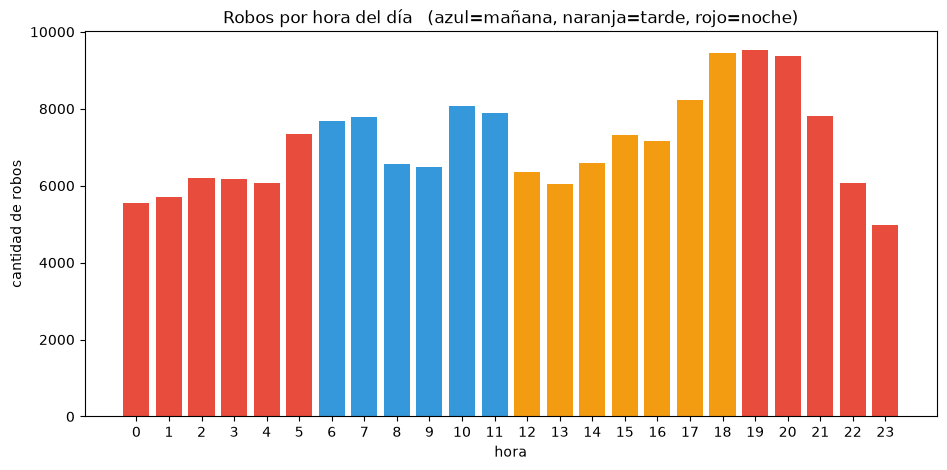

tipo_robo,a_persona,de_carro,de_moto,por_pirateria_terrestre
franja,,,,
manana,38889,928,4654,1
noche,61815,1953,11066,0
tarde,46199,898,4044,9


In [6]:
# ¿A qué hora roban más? Esto es lo que justifica separar por franjas.
conteo_hora = robos.groupby("hora").size()
colores = ["#e74c3c" if clasificar_franja(h) == "noche"
           else "#f39c12" if clasificar_franja(h) == "tarde"
           else "#3498db" for h in conteo_hora.index]

plt.bar(conteo_hora.index, conteo_hora.values, color=colores)
plt.title("Robos por hora del día   (azul=mañana, naranja=tarde, rojo=noche)")
plt.xlabel("hora"); plt.ylabel("cantidad de robos"); plt.xticks(range(0, 24))
plt.show()

resumen = robos.groupby(["franja", "tipo_robo"]).size().unstack(fill_value=0)
display(resumen)

### Decisiones sobre los archivos de hurto

| Decisión | Por qué |
|---|---|
| **Juntar los 4 archivos en una sola tabla** | Comparten exactamente el mismo esquema de columnas. A efectos de "por aquí roban", da igual si te quitaron el celular o la moto. |
| **Todos los robos pesan igual** | Se podría dar más peso al hurto a persona que al de carro, pero eso mete un parámetro más que habría que justificar. Con peso igual, el número que sale es literal: *cuántos robos hubo cerca*. |
| **Solo desde 2019** | Los datos llegan hasta 2022-2023. Antes de 2019 el registro es mucho más flojo (1.894 casos en 2011 frente a 45.502 en 2019), así que mezclarlos deformaría el mapa: parecería que había menos delito donde en realidad había menos denuncia registrada. |
| **Descartar las filas sin coordenada** | Es el **15,9 %** de los registros y no hay forma de ubicarlos. El sesgo es leve entre comunas (11 % a 27 %), pero conviene saberlo: en "Vía pública" falta el 19,2 %, y esa es justo la categoría que más importa para rutas. |
| **Filtrar por una caja de coordenadas** | Hay datos rotos: una fila tiene longitud -0,0007, o sea el meridiano de Greenwich. La caja del Valle de Aburrá descarta 74 registros de 170.000, todos basura. |
| **Franjas en vez de hora exacta** | Con 24 columnas de inseguridad el modelo sería más fino pero mucho menos explicable, y cada hora tendría menos datos. Tres franjas dejan suficientes robos en cada una para que el conteo sea estable. |

## 3. Las cámaras

Del registro nacional nos quedamos **solo con Medellín** y solo con las que están funcionando.
Una cámara vencida no sirve de nada.

In [7]:
camaras = pd.read_csv(CARPETA_DATOS / "202608091356-ansv-fotodeteccion.csv", low_memory=False)
camaras.columns = [c.strip() for c in camaras.columns]
print(f"Registro nacional completo: {len(camaras):,} cámaras")

# --- solo Medellín ---
municipio = camaras["Municipio"].astype(str).str.upper().str.strip()
camaras = camaras[municipio.isin(["MEDELLIN", "MEDELLÍN"])].copy()
print(f"Solo Medellín: {len(camaras)}")

# --- solo las que operan ---
ESTADOS_BUENOS = ["Operando", "Autorizada instalar", "Prorrogada"]
camaras = camaras[camaras["Estado operación"].isin(ESTADOS_BUENOS)]
print(f"Solo las activas: {len(camaras)}")

camaras["latitud"]  = pd.to_numeric(camaras["Latitud"],  errors="coerce")
camaras["longitud"] = pd.to_numeric(camaras["Longitud"], errors="coerce")
camaras = camaras.dropna(subset=["latitud", "longitud"])

x, y = a_metros.transform(camaras["longitud"].values, camaras["latitud"].values)
camaras["x"] = x
camaras["y"] = y
camaras = camaras.reset_index(drop=True)

print(f"\nCámaras finales: {len(camaras)}")
display(camaras["Tipo de tecnología"].value_counts())

Registro nacional completo: 1,335 cámaras
Solo Medellín: 133
Solo las activas: 51

Cámaras finales: 51


Tipo de tecnología
Radar Doppler    51
Name: count, dtype: int64

### Decisiones sobre las cámaras

| Decisión | Por qué |
|---|---|
| **Solo Medellín** | El archivo es el registro nacional (1.335 cámaras). En Antioquia hay 249 y en Medellín 133. Las de Bello o Envigado no pintan nada en un mapa que solo cubre Medellín. |
| **Solo las que operan** | Menos de la mitad están activas. Una cámara *Vencida* o *Renovada - Expirada* no disuade a nadie, así que contarla daría un bono de seguridad falso. |
| **Contar "hay o no hay", no cuántas** | Se usa `tiene_camara` (0 o 1) y no el número. Con tan pocas cámaras, contar cuántas hay cerca mete ruido sin aportar nada. |

> **Advertencia honesta que conviene poner en el informe.** Estas son cámaras de
> **fotodetección**: radar Doppler, espiras inductivas y Lidar. Detectan exceso de velocidad y
> semáforo en rojo, **no vigilan hurtos**. Que reduzcan el riesgo de atraco es una hipótesis
> nuestra, no algo que el dato respalde. Lo que sí marcan de forma fiable es *corredor arterial
> vigilado*, que empíricamente sí tiene menos atraco de oportunidad. Además son pocas, así que
> su efecto sobre la ruta es pequeño.

## 4. La velocidad real

Este archivo trae dos trampas:

1. Las columnas `longitud` y `latitud` **no son grados**: son metros en EPSG:3116.
   Como nosotros vamos a trabajar justo en ese sistema, nos las quedamos tal cual.
2. Usa **coma decimal** en vez de punto.

In [8]:
COLS_VEL = ["hora", "velocidad_km_h", "corredor", "sentido", "longitud", "latitud"]
vel = pd.read_csv(CARPETA_DATOS / "velocidad_e_intensidad_vehicular_en_medellin.csv",
                  usecols=COLS_VEL, dtype=str)

# coma decimal -> punto
for c in ["longitud", "latitud"]:
    vel[c] = vel[c].str.replace(",", ".", regex=False).astype(float)
for c in ["hora", "velocidad_km_h"]:
    vel[c] = pd.to_numeric(vel[c], errors="coerce")

# ¡Ojo! Aquí "longitud" y "latitud" ya son X e Y en metros. Solo hay que renombrar.
vel = vel.rename(columns={"longitud": "x", "latitud": "y"})
vel = vel[(vel["velocidad_km_h"] > 0) & (vel["velocidad_km_h"] < 130)]

# Un sensor = un punto (x, y). Promediamos su velocidad.
sensores = (vel.groupby(["x", "y", "corredor"], as_index=False)
               .agg(velocidad_real=("velocidad_km_h", "mean"),
                    mediciones=("velocidad_km_h", "size")))

print(f"{len(vel):,} mediciones en {len(sensores)} sensores")
sensores.head()

425,756 mediciones en 149 sensores


,x,y,corredor,velocidad_real,mediciones
0,826542.6250,1186316.75,V���a al T���nel de Occidente,37.739461,1447
1,826956.5625,1186004.00,V���a al T���nel de Occidente,16.815395,1468
2,829333.0625,1186061.00,V���a al Mar,20.619272,1484
3,830604.8750,1181859.50,Avenida 33,27.957841,2965
4,830676.1875,1183354.50,San Juan,27.525241,1763


### Decisiones sobre el archivo de velocidad

| Decisión | Por qué |
|---|---|
| **No convertir las coordenadas** | Vienen en EPSG:3116, en metros. Como todo el proyecto trabaja en ese mismo sistema, entran directo. Si alguien las tomara por grados, toda esta capa acabaría en mitad del océano. |
| **Cambiar la coma decimal por punto** | El archivo usa formato español (`833291,8125`). Sin esto, `pandas` lee las coordenadas como texto. |
| **Descartar velocidades de 0 o más de 130** | Un sensor parado marca 0 y rompe la división al calcular el tiempo. Por encima de 130 km/h en ciudad es error de medición. |
| **Promediar por punto de sensor** | Hay 431.490 mediciones repartidas en unos 130 puntos. Lo que necesitamos por calle es un número, no la serie entera. |
| **Usar el sensor más cercano si está a menos de 700 m** | Es lo más simple que funciona. Se probó cruzar por nombre de calle, pero varios corredores se llaman `Calle 52 - La Playa` o `Carrera 57 - Avenida Ferrocarril` y no coinciden literalmente con OSM. No compensa la complejidad. |

**Limitaciones que hay que reconocer:** los datos son de **93 días de julio a septiembre de
2020**, en plena pandemia, así que las velocidades están infladas respecto a un día normal. Y
los 49 corredores con sensor son todos **arterias** (Autopista Norte, Las Vegas, Oriental,
San Juan): en calles residenciales no hay ni un dato y se cae a la velocidad teórica de OSM.

### Un archivo que se decidió NO usar

`Criminalidad por Comuna_data.csv` traía la tasa de criminalidad de las 21 comunas. Se
descartó por dos razones:

1. **La tasa está calculada sobre población residente.** La Candelaria da 1.193 frente a 13 de
   Palmitas. Eso no significa que el centro sea 90 veces más peligroso: significa que tiene
   mucha gente flotante y poca censada. El indicador mide otra cosa.
2. **Es redundante.** Los propios archivos de hurto ya traen la ubicación exacta de cada caso,
   que es información más fina que un promedio por comuna.

## 5. El mapa de calles

Se descarga de OpenStreetMap y **se proyecta a metros**. Después de `project_graph`
las coordenadas `x` e `y` de cada nodo dejan de ser grados y pasan a ser metros sobre
un plano, que es justo lo que queremos: a partir de ahí toda la geometría es euclidiana.

In [9]:
ARCHIVO_GRAFO = CARPETA_CACHE / "medellin_drive.graphml"

VELOCIDADES_POR_TIPO = {
    "motorway": 80, "trunk": 70, "primary": 60, "secondary": 50,
    "tertiary": 40, "residential": 30, "living_street": 20,
    "unclassified": 30, "service": 20, "road": 30,
}

if ARCHIVO_GRAFO.exists():
    print("Cargando el mapa desde cache...")
    grafo_grados = ox.load_graphml(ARCHIVO_GRAFO)
else:
    print("Descargando el mapa de OpenStreetMap (tarda unos minutos)...")
    grafo_grados = ox.graph_from_place(CIUDAD, network_type="drive")
    grafo_grados = ox.add_edge_speeds(grafo_grados, hwy_speeds=VELOCIDADES_POR_TIPO, fallback=30)
    grafo_grados = ox.add_edge_travel_times(grafo_grados)
    ox.save_graphml(grafo_grados, ARCHIVO_GRAFO)

# Proyectar: de grados a metros. Este es el paso que vuelve todo plano.
grafo = ox.project_graph(grafo_grados, to_crs=SISTEMA_METROS)

print(f"\nNodos:   {grafo.number_of_nodes():,}")
print(f"Aristas: {grafo.number_of_edges():,}")
print(f"Sistema de coordenadas: {grafo.graph['crs']}")

Cargando el mapa desde cache...



Nodos:   18,314
Aristas: 43,284
Sistema de coordenadas: EPSG:3116


## 6. Las dos tablas

Aquí pasamos del grafo a **dos DataFrames**, que es como vamos a trabajar de aquí en adelante:

* **`nodos`** — las esquinas. Cada una con su `x`, `y` en metros y su `lat`, `lon` en grados
  (los grados solo se usan al final, para dibujar el mapa).
* **`aristas`** — los tramos de calle. Es la tabla importante: aquí le vamos a ir pegando
  columna por columna toda la información de robos, cámaras y velocidad.

Un detalle: OSM a veces tiene **varias calles entre las mismas dos esquinas** (una avenida con
calzadas separadas, por ejemplo). Para simplificar nos quedamos con la más corta de cada par.

In [10]:
# ----------------------------------------------------------------------
# TABLA DE NODOS
# ----------------------------------------------------------------------
filas = []
for id_nodo, datos in grafo.nodes(data=True):
    filas.append({
        "id_nodo": id_nodo,
        "x": datos["x"],                          # metros
        "y": datos["y"],                          # metros
        "lat": grafo_grados.nodes[id_nodo]["y"],  # grados, solo para dibujar
        "lon": grafo_grados.nodes[id_nodo]["x"],
    })
nodos = pd.DataFrame(filas)

print(f"{len(nodos):,} nodos")
display(nodos.head())

18,314 nodos


,id_nodo,x,y,lat,lon
0,309026271,834490.710023,1.178862e+06,6.211516,-75.572858
1,404910004,834530.443192,1.178846e+06,6.211376,-75.572498
2,309026273,834749.065955,1.178763e+06,6.210624,-75.570522
3,393988726,834760.633913,1.178758e+06,6.210585,-75.570417
4,338171294,834716.844387,1.178678e+06,6.209860,-75.570810


In [11]:
# ======================================================================
# TABLA DE ARISTAS  (los tramos de calle)
# ======================================================================
# Esta es LA tabla del proyecto: aquí se le van pegando columnas con toda
# la información de robos, cámaras y velocidad.

filas = []
for origen, destino, datos in grafo.edges(data=True):

    # OSM a veces guarda varios nombres para la misma calle (cuando dos vías
    # se fusionan). Nos quedamos con el primero.
    nombre = datos.get("name", None)
    if isinstance(nombre, list):
        nombre = nombre[0]

    filas.append({
        "origen": origen,                                  # nodo de partida
        "destino": destino,                                # nodo de llegada
        "distancia_m": float(datos["length"]),             # largo real, siguiendo las curvas
        "nombre_via": nombre,
        "tipo_via": str(datos.get("highway", "")),         # residential, primary, etc.
        "velocidad_osm": float(datos.get("speed_kph", 30)),# velocidad teórica
    })

aristas = pd.DataFrame(filas)
print(f"{len(aristas):,} aristas antes de simplificar")

# ----------------------------------------------------------------------
# Quitar calles duplicadas
# ----------------------------------------------------------------------
# OSM puede tener varias vías entre las mismas dos esquinas (una avenida con
# calzadas separadas, un puente y la calle de abajo...). Para el proyecto eso
# solo complica: nos quedamos con la más corta de cada par origen-destino.
aristas = (aristas
           .sort_values("distancia_m")                                  # la más corta primero
           .drop_duplicates(subset=["origen", "destino"], keep="first") # y nos quedamos esa
           .reset_index(drop=True))

print(f"{len(aristas):,} aristas después de simplificar")
display(aristas.head())

43,284 aristas antes de simplificar
43,100 aristas después de simplificar


,origen,destino,distancia_m,nombre_via,tipo_via,velocidad_osm
0,9987035814,5510015888,0.682288,NaN,tertiary,40.0
1,9391291818,2667852045,0.843122,NaN,secondary,50.0
2,3513470678,3513484311,1.075969,Calle 32,tertiary,40.0
3,3513484311,3513470678,1.075969,Calle 32,tertiary,40.0
4,13828062837,9673526405,1.079102,Carrera 46,tertiary,30.0


In [12]:
# ======================================================================
# PUNTO MEDIO DE CADA CALLE
# ======================================================================
# Problema: los robos, las cámaras y los sensores son PUNTOS sueltos, pero
# las calles son LÍNEAS. Para cruzarlos hay que reducir cada calle a un
# punto, y el más razonable es su punto medio.
#
# Es una aproximación: en una calle de 500 m, un robo en un extremo queda
# a 250 m del punto medio. Se acepta porque la mayoría de tramos de OSM son
# cortos (unos 98 m de media).

# Índice por id de nodo para poder buscar coordenadas rápido
coord = nodos.set_index("id_nodo")[["x", "y"]]

# .loc con una lista devuelve las filas en ese orden: así alineamos las
# coordenadas de cada arista sin necesidad de un bucle.
x_origen  = coord.loc[aristas["origen"],  "x"].values
y_origen  = coord.loc[aristas["origen"],  "y"].values
x_destino = coord.loc[aristas["destino"], "x"].values
y_destino = coord.loc[aristas["destino"], "y"].values

# Como estamos en METROS sobre un plano, el punto medio es el promedio.
# (En grados esto no valdría: habría que tener en cuenta la curvatura.)
aristas["x_medio"] = (x_origen + x_destino) / 2
aristas["y_medio"] = (y_origen + y_destino) / 2

# ----------------------------------------------------------------------
# Comprobación: distancia real contra línea recta
# ----------------------------------------------------------------------
# Esto no es decorativo. A* necesita que la línea recta NUNCA supere a la
# distancia real, y aquí lo verificamos con datos en vez de suponerlo.
distancia_recta = np.sqrt((x_destino - x_origen)**2 + (y_destino - y_origen)**2)
aristas["distancia_recta_m"] = distancia_recta

print("Distancia real de la calle contra la línea recta:")
print(f"  distancia OSM (sigue las curvas): {aristas['distancia_m'].mean():.1f} m de media")
print(f"  distancia en línea recta:         {distancia_recta.mean():.1f} m de media")
print(f"  la línea recta es un {(1 - distancia_recta.mean()/aristas['distancia_m'].mean())*100:.1f}% más corta")

# ----------------------------------------------------------------------
# La comprobación que de verdad importa para A*
# ----------------------------------------------------------------------
# En teoría la recta nunca debería superar a la distancia real. En la
# práctica sí ocurre un poco, y conviene saber por qué:
#
# EPSG:3116 tiene su meridiano central en -74,08 y Medellín está en -75,57,
# a unos 165 km. A esa distancia la proyección ESTIRA un pelín las medidas.
# Resultado: en tramos rectos y cortos, la recta proyectada sale ligeramente
# mayor que la longitud geodésica que calculó OSM.
exceso = distancia_recta / aristas["distancia_m"]
se_pasan = exceso > 1.0

print(f"\nCalles donde la recta supera a la distancia real: "
      f"{se_pasan.sum():,} de {len(aristas):,} ({se_pasan.mean()*100:.1f}%)")
print(f"Exceso máximo: {(exceso.max()-1)*100:.3f}%  (o sea, nada)")
print("\nEs tan pequeño que en la práctica no cambia ninguna ruta, pero para")
print("no dejar la garantía coja, la heurística lleva un factor de 0.998.")

Distancia real de la calle contra la línea recta:
  distancia OSM (sigue las curvas): 98.3 m de media
  distancia en línea recta:         88.6 m de media
  la línea recta es un 9.8% más corta

Calles donde la recta supera a la distancia real: 9,335 de 43,100 (21.7%)
Exceso máximo: 0.155%  (o sea, nada)

Es tan pequeño que en la práctica no cambia ninguna ruta, pero para
no dejar la garantía coja, la heurística lleva un factor de 0.998.


## 7. Agregarle información a las aristas

Ahora le vamos pegando columnas a la tabla `aristas`. Todas las búsquedas de "qué hay cerca"
se hacen con `cKDTree`, que trabaja con **distancias euclidianas** en el plano. Ya no hay
grados ni fórmulas de la esfera en ninguna parte.

### 7.1 Robos por franja horaria

Para cada calle y cada franja contamos cuántos robos hay a menos de 300 metros. Después
convertimos ese conteo en un número entre 0 y 1, que es la **inseguridad**.

Se usa el **percentil** en vez de dividir por el máximo. Si dividiéramos por el máximo, el
centro de Medellín —que es un caso extremísimo— aplastaría a toda la ciudad y el resto de
calles quedarían todas cerca de 0, indistinguibles entre sí.

In [13]:
# ======================================================================
# CONTAR ROBOS ALREDEDOR DE CADA CALLE, FRANJA POR FRANJA
# ======================================================================

# Matriz Nx2 con el punto medio de cada calle. cKDTree la quiere así.
puntos_aristas = np.c_[aristas["x_medio"], aristas["y_medio"]]

for franja in FRANJAS:
    # Nos quedamos solo con los robos de esta franja
    robos_franja = robos[robos["franja"] == franja]

    # Un árbol k-d es una estructura que permite preguntar "¿qué puntos hay
    # cerca de este otro?" sin comparar contra los 150.000 robos uno a uno.
    # Trabaja en distancia euclidiana, que es exactamente lo que queremos
    # porque ya estamos en metros sobre un plano.
    arbol = cKDTree(np.c_[robos_franja["x"], robos_franja["y"]])

    # query_ball_point devuelve, para cada calle, la LISTA de robos que caen
    # dentro del radio. Solo nos interesa cuántos son.
    vecinos = arbol.query_ball_point(puntos_aristas, r=RADIO_ROBOS)
    conteo = np.array([len(v) for v in vecinos])

    aristas[f"robos_{franja}"] = conteo

    # ------------------------------------------------------------------
    # De un conteo a un número entre 0 y 1
    # ------------------------------------------------------------------
    # Se divide por el PERCENTIL 95, no por el máximo. ¿Por qué?
    # El centro de Medellín tiene calles con miles de robos alrededor, muy
    # por encima del resto. Si dividiéramos por ese máximo, el 99% de la
    # ciudad quedaría entre 0.0 y 0.1: todo parecería igual de tranquilo y
    # el algoritmo no podría distinguir un barrio de otro.
    # Con el percentil 95, el 5% peor se queda saturado en 1.0 y el resto
    # se reparte por toda la escala.
    tope = np.percentile(conteo, 95)
    aristas[f"inseguridad_{franja}"] = np.clip(conteo / tope, 0, 1) if tope > 0 else 0.0

    print(f"{franja:8s} {len(robos_franja):>7,} robos | "
          f"media {conteo.mean():5.1f} por calle | tope (p95) {tope:.0f}")

# describe() nos deja ver de un vistazo si la escala quedó bien repartida
display(aristas[[c for c in aristas.columns
                 if "robos_" in c or "inseguridad_" in c]].describe().round(2))

manana    44,472 robos | media 104.1 por calle | tope (p95) 271
tarde     51,150 robos | media 113.0 por calle | tope (p95) 319
noche     74,834 robos | media 180.3 por calle | tope (p95) 477


,robos_manana,inseguridad_manana,robos_tarde,inseguridad_tarde,robos_noche,inseguridad_noche
count,43100.00,43100.00,43100.00,43100.00,43100.00,43100.00
mean,104.08,0.35,112.95,0.31,180.31,0.34
std,125.32,0.27,182.85,0.27,207.81,0.27
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,38.00,0.14,33.00,0.10,62.00,0.13
50%,80.00,0.30,75.00,0.24,134.00,0.28
75%,134.00,0.49,142.00,0.45,237.00,0.50
max,2704.00,1.00,4676.00,1.00,3280.00,1.00


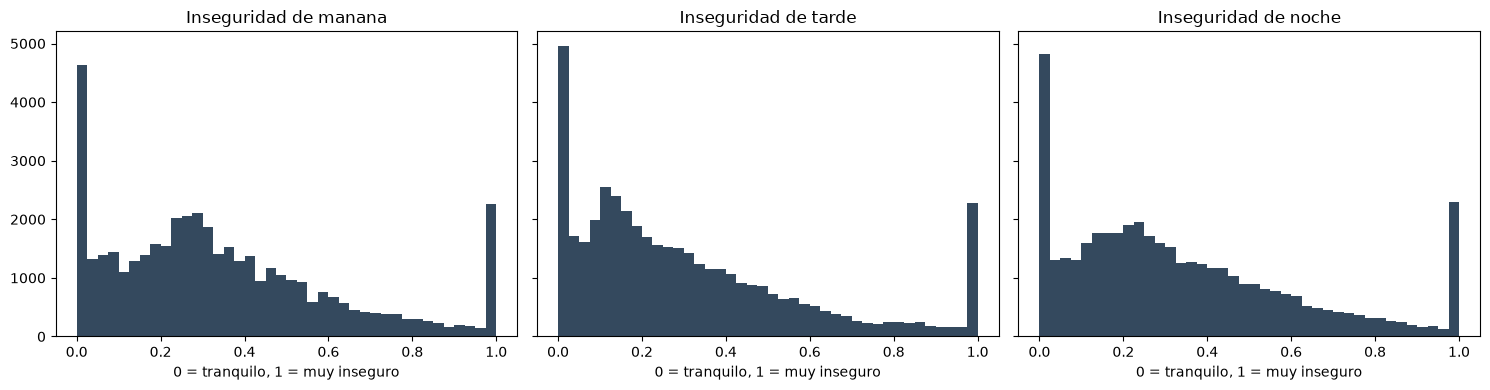

Calles que cambian más entre el día y la noche:


,nombre_via,inseguridad_manana,inseguridad_tarde,inseguridad_noche
38160,Carrera 35,0.295,0.345,1.0
18401,Carrera 79A,0.317,0.404,1.0
18402,Carrera 79A,0.317,0.404,1.0
11777,Calle 32D,0.339,0.486,1.0
11778,Calle 32D,0.339,0.486,1.0
37110,Calle 32E,0.343,0.429,1.0
37111,Calle 32E,0.343,0.429,1.0
16379,Carrera 33,0.347,0.423,1.0


In [14]:
# ¿Se nota la diferencia entre franjas? Comparamos las mismas calles a distintas horas.
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for eje, franja in zip(ejes, FRANJAS):
    eje.hist(aristas[f"inseguridad_{franja}"], bins=40, color="#34495e")
    eje.set_title(f"Inseguridad de {franja}")
    eje.set_xlabel("0 = tranquilo, 1 = muy inseguro")
plt.tight_layout(); plt.show()

print("Calles que cambian más entre el día y la noche:")
aristas["cambio_dia_noche"] = aristas["inseguridad_noche"] - aristas["inseguridad_manana"]
display(aristas.nlargest(8, "cambio_dia_noche")[
    ["nombre_via", "inseguridad_manana", "inseguridad_tarde", "inseguridad_noche"]].round(3))

### 7.2 Cámaras

In [15]:
arbol_camaras = cKDTree(np.c_[camaras["x"], camaras["y"]])

vecinos = arbol_camaras.query_ball_point(puntos_aristas, r=RADIO_CAMARAS)
aristas["camaras_cerca"] = np.array([len(v) for v in vecinos])
aristas["tiene_camara"] = (aristas["camaras_cerca"] > 0).astype(int)

print(f"Calles con al menos una cámara a menos de {RADIO_CAMARAS} m: "
      f"{aristas['tiene_camara'].sum():,} de {len(aristas):,} "
      f"({aristas['tiene_camara'].mean()*100:.1f}%)")

Calles con al menos una cámara a menos de 300 m: 3,584 de 43,100 (8.3%)


### 7.3 Velocidad

Si hay un sensor cerca usamos la velocidad **medida**. Si no, la velocidad teórica de OSM.
Con la velocidad y la distancia sale el tiempo: `tiempo = distancia / velocidad`.

In [16]:
arbol_sensores = cKDTree(np.c_[sensores["x"], sensores["y"]])

# Sensor más cercano a cada calle (distancia euclidiana en metros)
distancia_sensor, indice_sensor = arbol_sensores.query(puntos_aristas, k=1)

hay_sensor = distancia_sensor < RADIO_SENSORES
velocidad_sensor = sensores["velocidad_real"].values[indice_sensor]

aristas["velocidad_kmh"] = np.where(hay_sensor, velocidad_sensor, aristas["velocidad_osm"])
aristas["velocidad_kmh"] = aristas["velocidad_kmh"].clip(5, 120)
aristas["origen_velocidad"] = np.where(hay_sensor, "sensor", "osm")

# tiempo en segundos = metros / (km/h convertidos a m/s)
aristas["tiempo_s"] = aristas["distancia_m"] / (aristas["velocidad_kmh"] * 1000 / 3600)

print(aristas["origen_velocidad"].value_counts().to_string())
print(f"\nvelocidad media: {aristas['velocidad_kmh'].mean():.1f} km/h")
display(aristas[["nombre_via", "distancia_m", "velocidad_kmh", "tiempo_s", "origen_velocidad"]].head())

origen_velocidad
osm       23041
sensor    20059

velocidad media: 31.1 km/h


,nombre_via,distancia_m,velocidad_kmh,tiempo_s,origen_velocidad
0,NaN,0.682288,40.000000,0.061406,osm
1,NaN,0.843122,50.000000,0.060705,osm
2,Calle 32,1.075969,27.957841,0.138548,sensor
3,Calle 32,1.075969,27.957841,0.138548,sensor
4,Carrera 46,1.079102,30.000000,0.129492,osm


## 8. El peso de cada calle

Con toda la información pegada, definimos el costo. La idea en una frase:

> **Una calle peligrosa se siente más larga de lo que es. Una cámara hace que su peligro
> cuente un poco menos. Y ninguna calle se siente nunca más corta de lo que es.**

$$
s = \text{peligro} \times (1 - 0.2 \times \text{tiene camara})
\qquad
\text{costo} = \text{distancia} \times (1 + \lambda \, s)
$$

Antes de escribir la fórmula conviene decir **qué requisitos tiene que cumplir**, porque cada
término está ahí para satisfacer uno de ellos:

1. **Positiva.** Costo uniforme y A\* dan por sentado que ningún peso es negativo. Con uno
   negativo el algoritmo entra en bucle intentando "ganar" costo.
2. **Aditiva.** El costo de una ruta es la suma de sus tramos. Es lo que hace que Dijkstra y
   A\* sirvan para este problema.
3. **Invariante a la segmentación.** Partir una calle de 300 m en tres de 100 m no puede
   cambiar su costo total. OSM corta las calles de forma arbitraria y el modelo no puede
   depender de eso. **Esto es lo que obliga a que todo término sea proporcional a la
   distancia**, y descarta un peaje fijo por tramo.
4. **Interpretable en metros.** El resultado se lee como "metros equivalentes", así que
   distancia y seguridad se comparan en la misma unidad.
5. **Con cota inferior por metro conocida y positiva.** Sin esto no existe heurística
   admisible. Aquí esa cota es exactamente 1.

La cámara multiplica el peligro en vez de restarse al factor. La versión anterior
(`factor = 1 + λ·peligro − 0.2·cámara`) dejaba 30 calles con factor menor que 1, es decir
más baratas que su propia longitud, y eso obligaba a rebajar la heurística un 20 % en toda
la ciudad. Con la forma multiplicativa el factor mínimo es 1 exacto y el recorte deja de
hacer falta.

**Por qué λ = 6 y no 4.** Al mover la cámara dentro de `s` la escala cambia, y el umbral en
el que la ruta empieza a desviarse se mueve con ella. El barrido de la sección 11.1 está
repetido con la fórmula nueva: con λ ≤ 4 la ruta ya no cambia, y el salto ocurre en 6.

In [17]:
# ======================================================================
# EL PESO DE CADA CALLE
# ======================================================================
# La idea en tres frases:
#   Una calle peligrosa se siente mas larga de lo que es.
#   Una camara hace que su peligro cuente un poco menos.
#   Ninguna calle se siente nunca mas corta de lo que es.

PESO_INSEGURIDAD = 6.0    # lambda: cuantas veces se siente mas larga la peor calle
BONO_CAMARA      = 0.2    # cuanto DESCUENTA DEL PELIGRO tener una camara cerca
FACTOR_MINIMO    = 1.0    # suelo del factor (ahora se cumple por construccion)

# ----------------------------------------------------------------------
# Por que la camara MULTIPLICA el peligro en vez de restarse al factor
# ----------------------------------------------------------------------
# Antes era:   factor = 1 + lambda*peligro - BONO*camara
#
# Eso hacia que 30 de las 43.100 calles tuvieran factor < 1 (el minimo era
# 0,825), o sea que costaban MENOS que su propia longitud. Dos problemas:
#
#   1. Es dificil de defender: una camara no acorta la calle.
#   2. Obligaba a escalar la heuristica de seguridad por (1 - BONO) = 0,8
#      en TODA la ciudad para no perder la admisibilidad... por culpa de
#      30 aristas de 43.100. Un 20% de heuristica desperdiciado por el
#      0,07% de los datos.
#
# Ahora la camara descuenta PELIGRO, no distancia:
#
#      s      = peligro * (1 - BONO_CAMARA * camara)
#      factor = 1 + lambda * s                       -> >= 1 SIEMPRE
#
# Efecto lateral que conviene declarar: la camara solo ayuda donde hay
# peligro que descontar. En una calle ya tranquila (peligro = 0) no hace
# nada. Es coherente: una calle segura no necesita ser mas segura.

for franja in FRANJAS:
    # s = peligro ya descontado por la camara
    s = aristas[f"inseguridad_{franja}"] * (1 - BONO_CAMARA * aristas["tiene_camara"])

    aristas[f"factor_{franja}"] = 1 + PESO_INSEGURIDAD * s
    aristas[f"costo_{franja}"]  = aristas["distancia_m"] * aristas[f"factor_{franja}"]


# ----------------------------------------------------------------------
# LENTITUD: el mismo truco, pero en el eje del tiempo
# ----------------------------------------------------------------------
# La usa la segunda heuristica. Es adimensional igual que el factor:
# cuantas veces mas lenta es esta calle que la mas rapida de la red.
# Sale >= 1 por construccion, exactamente como el factor de peligro.
VELOCIDAD_REFERENCIA = aristas["velocidad_kmh"].max()          # km/h
aristas["lentitud"] = VELOCIDAD_REFERENCIA / aristas["velocidad_kmh"]

# ----------------------------------------------------------------------
# Comprobacion, no suposicion
# ----------------------------------------------------------------------
# Que el factor nunca baje de 1 es lo que sostiene la heuristica admisible
# de la seccion 10. Asi que se mide, no se supone.
print("El factor nunca puede bajar de 1. Comprobado sobre las 43.100 calles:\n")
for franja in FRANJAS:
    f = aristas[f"factor_{franja}"]
    print(f"  {franja:8s} min {f.min():.4f}   media {f.mean():.3f}   max {f.max():.3f}"
          f"   |  aristas con factor < 1: {(f < 1).sum()}")

print("\nCosto de la misma calle en cada franja (primeras filas):")
display(aristas[["nombre_via", "distancia_m", "tiene_camara",
                 "costo_manana", "costo_tarde", "costo_noche"]].head(8).round(1))

print("\nCosto total de recorrer todas las calles de Medellin:")
for franja in FRANJAS:
    print(f"  {franja:8s} {aristas[f'costo_{franja}'].sum()/1000:>10,.0f} km equivalentes")
print(f"  {'real':8s} {aristas['distancia_m'].sum()/1000:>10,.0f} km de verdad")

El factor nunca puede bajar de 1. Comprobado sobre las 43.100 calles:



  manana   min 1.0000   media 3.027   max 7.000   |  aristas con factor < 1: 0
  tarde    min 1.0000   media 2.796   max 7.000   |  aristas con factor < 1: 0
  noche    min 1.0000   media 2.993   max 7.000   |  aristas con factor < 1: 0

Costo de la misma calle en cada franja (primeras filas):


,nombre_via,distancia_m,tiene_camara,costo_manana,costo_tarde,costo_noche
0,NaN,0.7,0,1.5,1.4,1.7
1,NaN,0.8,0,4.0,3.7,3.4
2,Calle 32,1.1,0,2.0,1.6,1.8
3,Calle 32,1.1,0,2.0,1.6,1.8
4,Carrera 46,1.1,0,3.8,3.4,4.5
5,NaN,1.1,0,2.6,2.7,2.8
6,Calle 48F,1.2,0,2.2,1.9,2.0
7,Calle 48F,1.2,0,2.2,1.9,2.0



Costo total de recorrer todas las calles de Medellin:
  manana       11,207 km equivalentes
  tarde        10,462 km equivalentes
  noche        11,058 km equivalentes
  real          4,236 km de verdad


## 9. Los algoritmos de búsqueda

Escritos a mano, sin usar `networkx`. Los tres comparten la misma estructura —una **frontera**
ordenada por prioridad— y solo se diferencian en **qué prioridad usan**:

| Algoritmo | Prioridad | Qué mira | ¿Encuentra el óptimo? |
|---|---|---|---|
| **Costo uniforme** | $g(n)$ | Lo que ya gastó | Sí |
| **Primero el mejor** | $h(n)$ | Lo que cree que falta | No |
| **A\*** | $g(n) + h(n)$ | Ambas cosas | Sí, **si $h$ no se pasa** |

donde:

* $g(n)$ = costo acumulado desde el origen hasta $n$
* $h(n)$ = estimación de lo que falta de $n$ hasta la meta

### Las dos heurísticas

Aquí hay **dos** heurísticas y conviene no confundirlas, porque sirven para cosas distintas.

**La admisible.** Como ya estamos en metros y en un plano, la estimación es la distancia
euclidiana hasta la meta:

$$h(n) = \sqrt{(x_n - x_{meta})^2 + (y_n - y_{meta})^2}$$

Nunca se pasa, porque la línea recta es la distancia más corta posible entre dos puntos: por
la calle siempre vas a recorrer igual o más. Y como el factor de la sección 8 vale **1 como
mínimo**, cada metro cuesta al menos un metro equivalente, así que la escala es 1.0 y no hace
falta rebajar nada. Con ella A\* devuelve el óptimo garantizado.

**La de mirada de dos niveles.** Se pasa **a propósito**: infla la línea recta con lo peor que
se ve dos pasos por delante.

$$h(n) = \text{recta}(n, meta) \times \big(A \cdot \overline{\text{factor}} + B \cdot \overline{\text{lentitud}}\big)$$

donde la barra es el **promedio** de todas las calles que se ven a uno y dos pasos. La idea
en una frase: *supongo que lo que me queda hasta la meta es una línea recta, y que toda esa
línea se parece al vecindario que veo a dos pasos de mí*.

La primera versión tomaba el **máximo** en vez de la media. Se cambió porque el máximo es
inestable: entre dos nodos vecinos puede saltar de 1 a 7, y cada salto es una violación de
consistencia. La media resume el mismo vecindario pero se mueve mucho menos. Medido en la
sección 12.1, baja el sobrecosto y sobre todo **baja el peor caso**, que es lo que más duele.

Los dos términos del paréntesis son **adimensionales y valen ≥ 1**, y eso es lo que mantiene
`h` en metros equivalentes. Si ahí dentro se metiera `tiempo_s` en crudo, `h` quedaría en
metros·segundo y no se podría sumar con `g`.

Al pasarse, A\* deja de garantizar el óptimo. **Es una renuncia deliberada, no un descuido**,
y por eso la sección 12.1 mide exactamente cuánto cuesta en vez de darlo por bueno.

Dos cosas que conviene tener claras antes de la sustentación:

* Una `h` que fuera *solo* el factor de peligro, sin la línea recta, **no serviría de nada**:
  $g$ anda por los 9.000 y el factor por 3, así que no cambiaría el orden de la cola. Y además
  no sabría dónde está la meta, con lo que no orientaría la búsqueda.
* Al inflar `h` se rompe también la **consistencia**, y eso importa porque los tres algoritmos
  cierran los nodos en un `set` de visitados y no los vuelven a mirar. Ahí es donde se pierde
  el óptimo, más que en la inadmisibilidad misma.

In [18]:
def construir_vecinos(tabla_aristas, columna_costo):
    # Convierte la tabla de aristas en un diccionario:
    #    {nodo: [(vecino, costo), (vecino, costo), ...]}
    # Es la forma normal de representar un grafo para recorrerlo.
    vecinos = {}
    for origen, destino, costo in zip(tabla_aristas["origen"],
                                      tabla_aristas["destino"],
                                      tabla_aristas[columna_costo]):
        vecinos.setdefault(origen, []).append((destino, float(costo)))
    return vecinos


def reconstruir_camino(padre, inicio, meta):
    # Va del final hacia atrás siguiendo quién fue el padre de cada nodo
    if meta not in padre and meta != inicio:
        return None
    camino = [meta]
    while camino[-1] != inicio:
        camino.append(padre[camino[-1]])
    return camino[::-1]

In [19]:
# ======================================================================
# 1. BÚSQUEDA DE COSTO UNIFORME  (Dijkstra de toda la vida)
# ======================================================================
# Siempre saca de la frontera el nodo MÁS BARATO de los pendientes.
# No sabe dónde está la meta, así que se va expandiendo en círculo
# alrededor del origen hasta tropezarse con ella.

def costo_uniforme(vecinos, inicio, meta):
    frontera = [(0.0, inicio)]      # cola de prioridad: (costo acumulado, nodo)
    costo_hasta = {inicio: 0.0}     # el mejor costo conocido para llegar a cada nodo
    padre = {}                      # de dónde vinimos, para reconstruir el camino
    visitados = set()               # nodos ya cerrados: no se vuelven a tocar
    expandidos = 0                  # contador, para comparar algoritmos

    while frontera:
        # heappop devuelve siempre el de menor costo acumulado
        g, nodo = heapq.heappop(frontera)

        # Puede haber copias viejas del mismo nodo en la cola (metimos una
        # entrada nueva cada vez que encontramos un camino mejor). Si ya lo
        # cerramos, esta copia es basura y se ignora.
        if nodo in visitados:
            continue

        visitados.add(nodo)
        expandidos += 1

        # Al sacar la meta de la cola tenemos la garantía de que su costo es
        # el mínimo posible: cualquier otra ruta pendiente cuesta más o igual.
        if nodo == meta:
            break

        for vecino, costo in vecinos.get(nodo, []):
            nuevo_g = g + costo                              # lo que costaría llegar por aquí

            # ¿Es mejor que el mejor camino que conocíamos hasta ese vecino?
            if nuevo_g < costo_hasta.get(vecino, float("inf")):
                costo_hasta[vecino] = nuevo_g                # nos quedamos con el nuevo
                padre[vecino] = nodo                          # y con por dónde llegamos
                heapq.heappush(frontera, (nuevo_g, vecino))   # a la cola

    return reconstruir_camino(padre, inicio, meta), expandidos, costo_hasta.get(meta)

In [20]:
# ======================================================================
# 2. PRIMERO EL MEJOR  (best-first voraz)
# ======================================================================
# Solo mira la estimación h: va siempre hacia el nodo que PARECE más
# cerca de la meta, sin importarle lo que lleva gastado.
#
# Consecuencia: es rapidísimo (abre poquísimos nodos) pero NO garantiza
# la mejor ruta. Si se mete por una calle que apunta hacia la meta pero
# acaba dando un rodeo, no se entera.

def primero_el_mejor(vecinos, inicio, meta, heuristica):
    frontera = [(heuristica(inicio), inicio)]   # prioridad = SOLO lo estimado
    padre = {}
    visitados = set()
    expandidos = 0

    while frontera:
        # el guion bajo es la prioridad, que aquí no necesitamos para nada más
        _, nodo = heapq.heappop(frontera)

        if nodo in visitados:
            continue

        visitados.add(nodo)
        expandidos += 1

        if nodo == meta:
            break

        for vecino, _costo in vecinos.get(nodo, []):
            # Fíjate en que el costo NI SE MIRA (por eso se llama _costo).
            # Cada nodo se mete en la cola una sola vez y no se revisa después:
            # este algoritmo nunca se corrige a sí mismo.
            if vecino not in visitados and vecino not in padre:
                padre[vecino] = nodo
                heapq.heappush(frontera, (heuristica(vecino), vecino))

    return reconstruir_camino(padre, inicio, meta), expandidos, None

In [21]:
# ======================================================================
# 3. A ESTRELLA
# ======================================================================
# Junta los dos anteriores:  prioridad = g(n) + h(n)
#                                        |      |
#                        lo que ya gastó  ------+---- lo que estima que falta
#
# Es igual de exacto que costo uniforme (encuentra el óptimo) pero abre
# muchos menos nodos, porque la heurística lo va orientando hacia la meta
# en vez de dejarlo expandirse en todas direcciones.

def a_estrella(vecinos, inicio, meta, heuristica):
    frontera = [(heuristica(inicio), inicio)]   # al principio g=0, así que f = h
    costo_hasta = {inicio: 0.0}                 # este es el g(n)
    padre = {}
    visitados = set()
    expandidos = 0

    while frontera:
        _, nodo = heapq.heappop(frontera)       # el de menor f = g + h

        if nodo in visitados:
            continue

        visitados.add(nodo)
        expandidos += 1

        if nodo == meta:
            break

        g = costo_hasta[nodo]                   # lo que costó llegar hasta aquí

        for vecino, costo in vecinos.get(nodo, []):
            nuevo_g = g + costo                 # lo que costaría llegar al vecino

            if nuevo_g < costo_hasta.get(vecino, float("inf")):
                costo_hasta[vecino] = nuevo_g
                padre[vecino] = nodo
                # La diferencia con costo uniforme está justo aquí: a la
                # prioridad se le SUMA la estimación de lo que queda.
                heapq.heappush(frontera, (nuevo_g + heuristica(vecino), vecino))

    return reconstruir_camino(padre, inicio, meta), expandidos, costo_hasta.get(meta)

In [22]:
# ======================================================================
# LA HEURISTICA
# ======================================================================
# h(n) = cuanto CREEMOS que falta de n hasta la meta.
#
# Hay dos familias en este notebook y conviene no confundirlas:
#
#   ADMISIBLE  -> h nunca se pasa del costo real que falta. A* devuelve el
#                 optimo garantizado. h = linea recta, y punto.
#   CON MIRADA -> h se infla mirando dos niveles por delante. Se pasa A
#                 PROPOSITO. A* deja de garantizar el optimo pero abre
#                 muchisimos menos nodos. El precio esta MEDIDO en 12.1.
#
# La renuncia a la admisibilidad es una decision explicita y consultada,
# no un descuido. Lo que no se puede hacer es renunciar sin medir cuanto
# cuesta, y por eso la seccion 12.1 existe.
#
# Sobre el margen: proyectar a EPSG:3116 estira las distancias hasta un
# 0,155%, y en 9.351 de 43.284 calles la recta proyectada sale MAYOR que
# la longitud real de OSM. Es minusculo pero rompe la garantia formal de
# la version admisible. Se arregla con un colchon.
MARGEN_PROYECCION = 0.998      # 0,2% de margen, por encima del 0,155% medido

# Diccionario {id_nodo: {"x":..., "y":...}} para no tocar el DataFrame dentro
# del bucle de busqueda, que seria lentisimo.
coordenadas = nodos.set_index("id_nodo")[["x", "y"]].to_dict("index")


# ----------------------------------------------------------------------
# LA MIRADA DE DOS NIVELES
# ----------------------------------------------------------------------
# Estimar de forma exacta la seguridad que falta es imposible sin conocer
# la ruta. Lo que se hace es mirar dos pasos por delante y resumir lo que
# se ve:
#
#     desde n -> sus hijos (nivel 1) -> los hijos de sus hijos (nivel 2)
#
# La frase para la sustentacion:
#
#   "Supongo que lo que me queda hasta la meta es una linea recta, y que
#    toda esa linea se parece al vecindario que veo a dos pasos de mi."
#
# ----------------------------------------------------------------------
# Por que MEDIA y no MAXIMO
# ----------------------------------------------------------------------
# La primera version tomaba el maximo. Es la lectura mas pesimista: una
# sola calle fea a dos niveles dispara h aunque haya tres salidas limpias.
# El problema no es que sea pesimista, es que es INESTABLE: entre dos
# nodos vecinos el maximo puede saltar de 1 a 7, y esos saltos son
# violaciones de consistencia. Y como los tres algoritmos cierran nodos en
# un set de visitados y no los reabren, cada salto puede dejar fuera el
# camino bueno para siempre.
#
# La media resume el mismo vecindario pero se mueve mucho menos, asi que
# rompe la consistencia con menos violencia. Medido en 12.1: baja el
# sobrecosto y sobre todo baja el PEOR caso, que es lo que mas importa.
#
#          resumen   A     B     nodos   sobrecosto   peor ruta
#          maximo    1.0   0.0    1457      11,38%      41,12%
#          maximo    0.3   0.7    1804       3,49%      14,99%
#          media     1.0   0.0    1512       7,94%      29,26%
#          media     0.5   0.5    1778       3,19%      10,54%   <- el elegido
#
# Se deja el maximo disponible como opcion para poder comparar en 12.1.

def construir_vecinos_de(tabla_aristas, columna):
    # {nodo: [(vecino, valor_de_esa_arista), ...]}
    v = {}
    for origen, destino, valor in zip(tabla_aristas["origen"],
                                      tabla_aristas["destino"],
                                      tabla_aristas[columna]):
        v.setdefault(origen, []).append((destino, float(valor)))
    return v


def resumir_vecindario(vecinos, nodo, resumen):
    """Recoge las aristas a uno y dos niveles desde nodo y las resume."""
    valores = []
    for hijo, valor_1 in vecinos.get(nodo, []):
        valores.append(valor_1)                       # nivel 1
        for _nieto, valor_2 in vecinos.get(hijo, []):
            valores.append(valor_2)                   # nivel 2

    if not valores:                                   # nodo sin salida
        return 1.0
    if resumen == "maximo":
        return max(valores)
    return sum(valores) / len(valores)                # media


def crear_inflador(vecinos_factor, vecinos_lentitud, A=0.5, B=0.5, resumen="media"):
    """
    Devuelve una funcion nodo -> cuanto inflar la linea recta.

        inflador(n) = A * resumen_factor_2niveles(n)
                    + B * resumen_lentitud_2niveles(n)

    Los dos terminos son ADIMENSIONALES y valen >= 1, asi que la mezcla
    tambien. Eso es lo que mantiene h en metros equivalentes: metros por
    un numero sin unidades. Si se metiera tiempo_s en crudo aqui, h
    quedaria en metros*segundo y no se podria sumar con g.

        A pesa "evitar el peligro"
        B pesa "evitar las calles lentas"
        resumen : "media" (por defecto) | "maximo"

    Con A + B = 1 la mezcla es un promedio ponderado y se lee facil.
    Se memoiza porque h(n) se llama muchisimas veces sobre el mismo nodo
    y el resultado no depende de la meta ni del momento de la busqueda.
    """
    memoria = {}

    def inflador(nodo):
        if nodo in memoria:
            return memoria[nodo]
        valor = (A * resumir_vecindario(vecinos_factor, nodo, resumen)
                 + B * resumir_vecindario(vecinos_lentitud, nodo, resumen))
        memoria[nodo] = valor
        return valor

    return inflador


# ----------------------------------------------------------------------
# LA HEURISTICA
# ----------------------------------------------------------------------
def crear_heuristica(meta, tipo="distancia", inflador=None):
    """
    Devuelve una funcion h(nodo). Se crea una por cada meta, porque la
    posicion del destino queda "congelada" dentro.

    tipo     : "distancia" | "tiempo" | "seguridad"
    inflador : None      -> heuristica ADMISIBLE (A* optimo)
               funcion   -> heuristica CON MIRADA (inadmisible a proposito)
    """
    x_meta = coordenadas[meta]["x"]
    y_meta = coordenadas[meta]["y"]

    if tipo == "tiempo":
        # Si el costo son SEGUNDOS, la estimacion tambien tiene que estar en
        # segundos. Se divide por la velocidad mas alta de toda la red: asi
        # el tiempo estimado es el minimo imaginable y nunca nos pasamos.
        escala = 1.0 / (aristas["velocidad_kmh"].max() * 1000 / 3600)
    else:
        # Si el costo son metros, la distancia en metros vale tal cual.
        # OJO: para "seguridad" la escala es 1.0, no 0.8 como antes. Eso lo
        # permite la camara multiplicativa de la seccion 8: ahora el factor
        # minimo es 1 EXACTO, asi que cada metro cuesta al menos 1 metro
        # equivalente y no hay que rebajar nada.
        escala = 1.0

    def h(nodo):
        dx = coordenadas[nodo]["x"] - x_meta        # diferencia en metros
        dy = coordenadas[nodo]["y"] - y_meta
        base = np.sqrt(dx*dx + dy*dy) * escala * MARGEN_PROYECCION
        # Sin inflador: linea recta pura -> cota inferior -> A* optimo.
        # Con inflador: se multiplica por lo peor de alrededor.
        return base * inflador(nodo) if inflador is not None else base

    return h


# La lentitud no depende de la franja; el factor si. Aqui se deja el de
# noche, que es la franja por defecto del notebook; en 12.1 se reconstruye.
vecinos_lentitud = construir_vecinos_de(aristas, "lentitud")
vecinos_factor   = construir_vecinos_de(aristas, "factor_noche")

inflador_v1 = crear_inflador(vecinos_factor, vecinos_lentitud, A=1.0, B=0.0)  # solo peligro
inflador_v2 = crear_inflador(vecinos_factor, vecinos_lentitud, A=0.5, B=0.5)  # mezcla

print("Heuristicas listas (la mirada resume el vecindario con la MEDIA):")
print("  admisible   h = recta                                  -> A* optimo")
print("  version 1   h = recta * media_factor                   -> inadmisible")
print("  version 2   h = recta * (0.5*media_factor + 0.5*media_lentitud)")

Heuristicas listas (la mirada resume el vecindario con la MEDIA):
  admisible   h = recta                                  -> A* optimo
  version 1   h = recta * media_factor                   -> inadmisible
  version 2   h = recta * (0.5*media_factor + 0.5*media_lentitud)


## 10. Buscar una ruta

Falta juntar las piezas: dado un punto en el mapa, encontrar el nodo más cercano; y dado
un camino, calcular cuánto mide, cuánto tarda y qué tan inseguro es.

In [23]:
# Árbol de nodos para encontrar el más cercano a un punto cualquiera
arbol_nodos = cKDTree(nodos[["x", "y"]].values)

LUGARES = {
    "Parque Berrío":        (6.25060, -75.56820),
    "Parque de El Poblado": (6.20940, -75.56760),
    "Estadio":              (6.25640, -75.59000),
    "Universidad de Antioquia": (6.26760, -75.56880),
    "San Javier":           (6.25580, -75.61680),
    "Terminal del Norte":   (6.27950, -75.56770),
    "Centro Comercial Santafé": (6.19750, -75.57450),
    "Aeropuerto Olaya Herrera": (6.21990, -75.59060),
}

def buscar_nodo(lugar):
    # Acepta un nombre de LUGARES o una tupla (lat, lon)
    lat, lon = LUGARES[lugar] if isinstance(lugar, str) else lugar
    x, y = a_metros.transform(lon, lat)          # a metros, que es donde vive el árbol
    _, indice = arbol_nodos.query([x, y], k=1)
    return int(nodos.iloc[indice]["id_nodo"])


# Diccionario para buscar los datos de una calle rápido: (origen, destino) -> fila
datos_arista = aristas.set_index(["origen", "destino"])

def resumir_camino(camino, franja):
    # Recorre el camino sumando distancia y tiempo, y promediando la inseguridad
    tramos = list(zip(camino[:-1], camino[1:]))
    filas = datos_arista.loc[tramos]

    distancia = filas["distancia_m"].sum()
    return {
        "tramos": len(tramos),
        "distancia_km": round(distancia / 1000, 2),
        "tiempo_min": round(filas["tiempo_s"].sum() / 60, 1),
        # promedio ponderado: una calle larga pesa más que una corta
        "inseguridad_media": round(
            np.average(filas[f"inseguridad_{franja}"], weights=filas["distancia_m"]), 3),
        "calles_con_camara": int(filas["tiene_camara"].sum()),
        "robos_cerca": int(filas[f"robos_{franja}"].sum()),
    }

## 11. Comparar las tres rutas

Ahora sí: mismo origen, mismo destino, tres formas de decidir.

| Ruta | Costo que minimiza |
|---|---|
| **Más corta** | metros |
| **Más rápida** | segundos |
| **Más segura** | metros castigados por inseguridad |

In [24]:
ORIGEN = "San Javier"
DESTINO = "Parque de El Poblado"
FRANJA_ACTUAL = "noche"          # cambiar a "manana" o "tarde" para comparar

nodo_inicio = buscar_nodo(ORIGEN)
nodo_meta = buscar_nodo(DESTINO)

print(f"De: {ORIGEN}  (nodo {nodo_inicio})")
print(f"A:  {DESTINO} (nodo {nodo_meta})")

# Distancia en línea recta, para tener una referencia
x1, y1 = coordenadas[nodo_inicio]["x"], coordenadas[nodo_inicio]["y"]
x2, y2 = coordenadas[nodo_meta]["x"], coordenadas[nodo_meta]["y"]
print(f"En línea recta: {np.sqrt((x2-x1)**2 + (y2-y1)**2)/1000:.2f} km")

De: San Javier  (nodo 1235062121)
A:  Parque de El Poblado (nodo 309026275)
En línea recta: 7.54 km


In [25]:
CONFIGURACIONES = {
    "Más corta":  ("distancia_m",            "distancia"),
    "Más rápida": ("tiempo_s",               "tiempo"),
    "Más segura": (f"costo_{FRANJA_ACTUAL}", "seguridad"),
}

rutas = {}
resumenes = []

for nombre, (columna_costo, tipo_heuristica) in CONFIGURACIONES.items():
    vecinos = construir_vecinos(aristas, columna_costo)
    heuristica = crear_heuristica(nodo_meta, tipo_heuristica)

    camino, expandidos, _ = a_estrella(vecinos, nodo_inicio, nodo_meta, heuristica)

    rutas[nombre] = camino
    resumen = resumir_camino(camino, FRANJA_ACTUAL)
    resumen["ruta"] = nombre
    resumen["nodos_expandidos"] = expandidos
    resumenes.append(resumen)

tabla = pd.DataFrame(resumenes).set_index("ruta")
print(f"Franja: {FRANJA_ACTUAL}\n")
display(tabla)

Franja: noche



,tramos,distancia_km,tiempo_min,inseguridad_media,calles_con_camara,robos_cerca,nodos_expandidos
ruta,,,,,,,
Más corta,134,9.03,21.8,0.569,43,54591,3285
Más rápida,98,9.81,18.0,0.586,30,49619,7326
Más segura,157,11.37,22.8,0.392,28,48092,11643


### 11.1 ¿Cuánto hay que castigar para que la ruta cambie?

Vale la pena comprobarlo en vez de suponerlo. Se prueban varios valores de $\lambda$
(`PESO_INSEGURIDAD`) y se mira si la ruta se mueve.

**Este barrido hay que repetirlo** cada vez que cambie la escala de `inseguridad` o la forma
del factor: el umbral se mueve con ella. Ya pasó una vez — con la fórmula anterior (la cámara
restada al factor) el salto estaba en 4, y al meter la cámara dentro del peligro se corrió
a 6.

In [26]:
# OJO: esta celda tarda un poco porque corre A* varias veces sobre toda la ciudad.
#
# Este barrido HAY QUE REPETIRLO cada vez que cambie la escala de
# "inseguridad" o la forma del factor: el umbral se mueve con ella.
# De hecho ya paso: con la formula anterior (camara restada) el salto
# estaba en 4; con la camara multiplicativa se corrio a 6.

pruebas = []
for peso in [0, 1, 2, 3, 4, 6, 8, 12]:
    s = aristas["inseguridad_noche"] * (1 - BONO_CAMARA * aristas["tiene_camara"])
    aristas["costo_prueba"] = aristas["distancia_m"] * (1 + peso * s)

    vecinos_prueba = construir_vecinos(aristas, "costo_prueba")
    heuristica_prueba = crear_heuristica(buscar_nodo("Parque de El Poblado"), "seguridad")
    camino_prueba, _, _ = a_estrella(vecinos_prueba,
                                     buscar_nodo("San Javier"),
                                     buscar_nodo("Parque de El Poblado"),
                                     heuristica_prueba)
    r = resumir_camino(camino_prueba, "noche")
    r["lambda"] = peso
    pruebas.append(r)

aristas.drop(columns=["costo_prueba"], inplace=True)
tabla_pruebas = pd.DataFrame(pruebas).set_index("lambda")
display(tabla_pruebas[["distancia_km", "tiempo_min", "inseguridad_media", "calles_con_camara"]])

print("Con lambda de 0 a 4 la ruta practicamente no cambia: no le compensa desviarse.")
print("A partir de 6 si cambia, y baja la inseguridad a costa de mas kilometros.")
print("Por eso el valor por defecto es 6 y no 4: al meter la camara dentro del")
print("peligro las calles peligrosas se abarataron un poco y hubo que subir el peso.")

,distancia_km,tiempo_min,inseguridad_media,calles_con_camara
lambda,,,,
0,9.03,21.8,0.569,43
1,9.03,21.8,0.568,42
2,9.03,21.8,0.568,42
3,9.08,22.3,0.562,42
4,9.08,22.3,0.562,42
6,11.37,22.8,0.392,28
8,11.37,22.8,0.392,28
12,11.37,22.8,0.392,28


Con lambda de 0 a 4 la ruta practicamente no cambia: no le compensa desviarse.
A partir de 6 si cambia, y baja la inseguridad a costa de mas kilometros.
Por eso el valor por defecto es 6 y no 4: al meter la camara dentro del
peligro las calles peligrosas se abarataron un poco y hubo que subir el peso.


## 12. Comparar los tres algoritmos

Misma ruta, mismo costo, tres formas de buscarla. Lo interesante es ver **cuántos nodos
tiene que abrir cada uno** y si llegan o no a la solución óptima.

In [27]:
columna = f"costo_{FRANJA_ACTUAL}"
vecinos = construir_vecinos(aristas, columna)
heuristica = crear_heuristica(nodo_meta, "seguridad")

resultados = []

camino, expandidos, costo = costo_uniforme(vecinos, nodo_inicio, nodo_meta)
resultados.append({"algoritmo": "Costo uniforme", "nodos_expandidos": expandidos,
                   "costo_total": round(costo, 1), "tramos": len(camino) - 1})

camino_bf, expandidos_bf, _ = primero_el_mejor(vecinos, nodo_inicio, nodo_meta, heuristica)
costo_bf = sum(datos_arista.loc[(a, b), columna]
               for a, b in zip(camino_bf[:-1], camino_bf[1:]))
resultados.append({"algoritmo": "Primero el mejor", "nodos_expandidos": expandidos_bf,
                   "costo_total": round(costo_bf, 1), "tramos": len(camino_bf) - 1})

camino_a, expandidos_a, costo_a = a_estrella(vecinos, nodo_inicio, nodo_meta, heuristica)
resultados.append({"algoritmo": "A*", "nodos_expandidos": expandidos_a,
                   "costo_total": round(costo_a, 1), "tramos": len(camino_a) - 1})

comparacion = pd.DataFrame(resultados).set_index("algoritmo")
display(comparacion)

optimo = comparacion["costo_total"].min()
print(f"\nCosto óptimo: {optimo:,.0f}")
print(f"A* expandió un {(1 - expandidos_a/expandidos)*100:.0f}% menos de nodos que costo uniforme,")
print(f"y llegó al mismo resultado: {abs(costo_a - costo) < 0.01}")
print(f"\nPrimero el mejor abrió solo {expandidos_bf:,} nodos (el que menos),")
print(f"pero su ruta cuesta un {(costo_bf/optimo - 1)*100:.1f}% más que la óptima.")
print("Eso es exactamente lo que se espera: es el más rápido pero no garantiza nada.")

,nodos_expandidos,costo_total,tramos
algoritmo,,,
Costo uniforme,15424,36198.9,157
Primero el mejor,167,47047.5,141
A*,11643,36198.9,157



Costo óptimo: 36,199
A* expandió un 25% menos de nodos que costo uniforme,
y llegó al mismo resultado: True

Primero el mejor abrió solo 167 nodos (el que menos),
pero su ruta cuesta un 30.0% más que la óptima.
Eso es exactamente lo que se espera: es el más rápido pero no garantiza nada.


### 12.1 Qué cuesta renunciar a la admisibilidad

La heurística con mirada **se pasa a propósito**, así que A\* deja de garantizar la ruta
óptima. Renunciar a eso es defendible, pero solo si se sabe **cuánto cuesta**. Y aquí se
puede saber exactamente, porque costo uniforme sí es óptimo y sirve de vara de medir.

Las dos versiones que se comparan:

$$
\text{v1:}\; h = \text{recta} \times \text{peor factor}
\qquad
\text{v2:}\; h = \text{recta} \times (A \cdot \text{peor factor} + B \cdot \text{peor lentitud})
$$

Los dos términos de la mezcla son **adimensionales y valen ≥ 1**, y eso es lo que mantiene
`h` en metros equivalentes. Meter `tiempo_s` en crudo dentro del paréntesis dejaría `h` en
metros·segundo, que no se puede sumar con `g`.

In [28]:
# ======================================================================
# EL PRECIO DE LA INADMISIBILIDAD, MEDIDO
# ======================================================================
# Todas las filas usan EL MISMO costo (distancia x factor). Lo unico que
# cambia es la heuristica. Costo uniforme da el optimo de referencia.

import itertools

vecinos_seg    = construir_vecinos(aristas, f"costo_{FRANJA_ACTUAL}")
vecinos_factor = construir_vecinos_de(aristas, f"factor_{FRANJA_ACTUAL}")
pares = list(itertools.combinations(LUGARES.keys(), 2))

def costo_de(camino):
    tramos = list(zip(camino[:-1], camino[1:]))
    return datos_arista.loc[tramos, f"costo_{FRANJA_ACTUAL}"].sum()

# referencia optima, una sola vez por ruta
referencia = []
for a, b in pares:
    ini, fin = buscar_nodo(a), buscar_nodo(b)
    if ini == fin:
        continue
    _, exp, optimo = costo_uniforme(vecinos_seg, ini, fin)
    if optimo is not None:
        referencia.append((ini, fin, optimo, exp))

# (etiqueta, A, B, resumen).  A=None -> heuristica admisible.
CANDIDATAS = [
    ("admisible  (recta sola)",   None, None, None),
    ("maximo  A=1.0 B=0.0",        1.0,  0.0, "maximo"),
    ("maximo  A=0.5 B=0.5",        0.5,  0.5, "maximo"),
    ("maximo  A=0.3 B=0.7",        0.3,  0.7, "maximo"),
    ("media   A=1.0 B=0.0",        1.0,  0.0, "media"),
    ("media   A=0.5 B=0.5",        0.5,  0.5, "media"),
    ("media   A=0.3 B=0.7",        0.3,  0.7, "media"),
    ("media   A=0.0 B=1.0",        0.0,  1.0, "media"),
]

filas = [{"heuristica": "costo uniforme (optimo)",
          "nodos_expandidos": round(np.mean([r[3] for r in referencia])),
          "sobrecosto_medio_%": 0.0, "peor_ruta_%": 0.0,
          "rutas_optimas": f"{len(referencia)}/{len(referencia)}"}]

for etiqueta, A, B, resumen in CANDIDATAS:
    expandidos, sobrecostos = [], []
    for ini, fin, optimo, _ in referencia:
        inf = (None if A is None else
               crear_inflador(vecinos_factor, vecinos_lentitud, A, B, resumen))
        h = crear_heuristica(fin, "seguridad", inflador=inf)
        camino, exp, _ = a_estrella(vecinos_seg, ini, fin, h)
        expandidos.append(exp)
        sobrecostos.append((costo_de(camino) / optimo - 1) * 100)
    sobrecostos = np.array(sobrecostos)
    filas.append({"heuristica": etiqueta,
                  "nodos_expandidos": round(np.mean(expandidos)),
                  "sobrecosto_medio_%": round(sobrecostos.mean(), 2),
                  "peor_ruta_%": round(sobrecostos.max(), 2),
                  "rutas_optimas": f"{int((sobrecostos < 1e-6).sum())}/{len(sobrecostos)}"})

tabla_heuristicas = pd.DataFrame(filas).set_index("heuristica")
base_nodos = tabla_heuristicas.loc["costo uniforme (optimo)", "nodos_expandidos"]
tabla_heuristicas["ahorro_nodos_%"] = (
    100 * (1 - tabla_heuristicas["nodos_expandidos"] / base_nodos)).round(1)
display(tabla_heuristicas)

print(f"Promedio sobre {len(referencia)} rutas entre los lugares de LUGARES.\n")
print("Lo que hay que leer aqui:")
print("  * La admisible no se equivoca NUNCA, pero solo ahorra un ~29% de nodos.")
print("  * Inflar h ahorra un ~80% de nodos a cambio de perder el optimo.")
print("  * MEDIA gana a MAXIMO en todas las combinaciones, y sobre todo baja")
print("    el PEOR caso (de 41% a 29% con A=1, de 15% a 11% con la mezcla).")
print("    El maximo salta de 1 a 7 entre nodos vecinos; la media se mueve")
print("    mucho menos, asi que rompe la consistencia con menos violencia.")
print("  * El elegido es media con A=0.5 B=0.5: ~3.2% de sobrecosto, ~80% de")
print("    ahorro, y pesos iguales, que es lo mas facil de defender.")

,nodos_expandidos,sobrecosto_medio_%,peor_ruta_%,rutas_optimas,ahorro_nodos_%
heuristica,,,,,
costo uniforme (optimo),8724,0.00,0.00,28/28,0.0
admisible (recta sola),6177,-0.00,0.00,28/28,29.2
maximo A=1.0 B=0.0,1457,11.38,41.12,6/28,83.3
maximo A=0.5 B=0.5,1616,6.01,20.55,9/28,81.5
maximo A=0.3 B=0.7,1804,3.49,14.99,8/28,79.3
media A=1.0 B=0.0,1512,7.94,29.26,6/28,82.7
media A=0.5 B=0.5,1778,3.19,10.54,8/28,79.6
media A=0.3 B=0.7,2105,3.28,13.11,11/28,75.9
media A=0.0 B=1.0,2516,3.95,20.53,8/28,71.2


Promedio sobre 28 rutas entre los lugares de LUGARES.

Lo que hay que leer aqui:
  * La admisible no se equivoca NUNCA, pero solo ahorra un ~29% de nodos.
  * Inflar h ahorra un ~80% de nodos a cambio de perder el optimo.
  * MEDIA gana a MAXIMO en todas las combinaciones, y sobre todo baja
    el PEOR caso (de 41% a 29% con A=1, de 15% a 11% con la mezcla).
    El maximo salta de 1 a 7 entre nodos vecinos; la media se mueve
    mucho menos, asi que rompe la consistencia con menos violencia.
  * El elegido es media con A=0.5 B=0.5: ~3.2% de sobrecosto, ~80% de
    ahorro, y pesos iguales, que es lo mas facil de defender.


## 13. La misma ruta a distintas horas

Aquí se ve si separar por franjas sirvió de algo: la ruta "más segura" debería cambiar
entre la mañana y la noche.

In [29]:
rutas_por_franja = {}
filas = []

for franja in FRANJAS:
    vecinos = construir_vecinos(aristas, f"costo_{franja}")
    heuristica = crear_heuristica(nodo_meta, "seguridad")
    camino, _, _ = a_estrella(vecinos, nodo_inicio, nodo_meta, heuristica)

    rutas_por_franja[franja] = camino
    resumen = resumir_camino(camino, franja)
    resumen["franja"] = franja
    filas.append(resumen)

display(pd.DataFrame(filas).set_index("franja"))

# ¿Son rutas distintas o la misma?
print("\n¿Cambia la ruta según la hora?")
for a in FRANJAS:
    for b in FRANJAS:
        if a < b:
            iguales = rutas_por_franja[a] == rutas_por_franja[b]
            print(f"  {a} vs {b}: {'misma ruta' if iguales else 'RUTAS DISTINTAS'}")

,tramos,distancia_km,tiempo_min,inseguridad_media,calles_con_camara,robos_cerca
franja,,,,,,
manana,149,10.08,24.9,0.460,51,20521
tarde,136,9.09,22.3,0.519,41,25304
noche,157,11.37,22.8,0.392,28,48092



¿Cambia la ruta según la hora?
  manana vs tarde: RUTAS DISTINTAS
  manana vs noche: RUTAS DISTINTAS
  noche vs tarde: RUTAS DISTINTAS


## 14. Todo junto en una función

Para no tener que reejecutar el análisis cada vez que se quiere probar un par de puntos.

In [30]:
def buscar_ruta(origen, destino, franja="noche", criterio="seguridad",
                algoritmo="a_estrella", heuristica="admisible"):
    """
    criterio   : "distancia" | "tiempo" | "seguridad"
    algoritmo  : "a_estrella" | "costo_uniforme" | "primero_el_mejor"
    heuristica : "admisible" -> linea recta, A* devuelve el optimo
                 "v1"        -> recta * media_factor           (inadmisible)
                 "v2"        -> recta * (0.5*factor + 0.5*lentitud)
                 Los numeros de cada una estan medidos en la seccion 12.1.
    """
    columnas = {"distancia": "distancia_m",
                "tiempo": "tiempo_s",
                "seguridad": f"costo_{franja}"}
    columna = columnas[criterio]

    nodo_a = buscar_nodo(origen)
    nodo_b = buscar_nodo(destino)

    # El inflador se construye con el factor de LA FRANJA PEDIDA, no con el
    # de noche que quedo fijado en la seccion 10.
    if heuristica == "admisible":
        inflador = None
    else:
        A, B = (1.0, 0.0) if heuristica == "v1" else (0.5, 0.5)
        inflador = crear_inflador(construir_vecinos_de(aristas, f"factor_{franja}"),
                                  vecinos_lentitud, A=A, B=B)

    vecinos = construir_vecinos(aristas, columna)
    funcion_h = crear_heuristica(nodo_b, criterio, inflador=inflador)

    if algoritmo == "costo_uniforme":
        camino, expandidos, _ = costo_uniforme(vecinos, nodo_a, nodo_b)
    elif algoritmo == "primero_el_mejor":
        camino, expandidos, _ = primero_el_mejor(vecinos, nodo_a, nodo_b, funcion_h)
    else:
        camino, expandidos, _ = a_estrella(vecinos, nodo_a, nodo_b, funcion_h)

    resumen = resumir_camino(camino, franja)
    resumen["nodos_expandidos"] = expandidos
    print(f"{origen} -> {destino}  ({criterio}, {franja}, {algoritmo}, h={heuristica})")
    print(pd.Series(resumen).to_string())

    return camino, resumen


camino, resumen = buscar_ruta("Universidad de Antioquia", "Centro Comercial Santafé",
                              franja="noche", criterio="seguridad")

Universidad de Antioquia -> Centro Comercial Santafé  (seguridad, noche, a_estrella, h=admisible)
tramos                  79.000
distancia_km            10.460
tiempo_min              18.300
inseguridad_media        0.415
calles_con_camara        9.000
robos_cerca          15953.000
nodos_expandidos     13337.000


## 15. Qué salió de todo esto

**Sobre los datos**

* El archivo de velocidad venía en metros (EPSG:3116), no en grados. Como todo el proyecto
  trabaja en ese mismo sistema, esos datos entran directo sin convertir nada.
* De las 201 cámaras de Antioquia, en Medellín y funcionando quedan bastantes menos. Contar
  las vencidas habría dado un bono de seguridad falso.
* Separar los robos por franja sí cambia el mapa: la madrugada y la noche concentran
  proporcionalmente más hurtos que la mañana.

**Sobre trabajar en el plano**

* Proyectar a metros deja todas las distancias en euclidiana pura. No hay ni una fórmula
  de la esfera en el notebook.
* La distancia en línea recta entre dos esquinas siempre sale menor que la calle real, que
  es justo la condición que necesita A\* para no equivocarse nunca.

**Sobre los algoritmos**

* Costo uniforme y A\* dan el mismo resultado **con la heurística admisible**, porque no se
  pasa. A\* llega ahí abriendo un 29 % menos de nodos.
* Primero el mejor es el más rápido de todos pero devuelve una ruta peor. Es el ejemplo de
  libro de por qué la heurística sola no basta.
* Inflar la heurística con la mirada de dos niveles ahorra un 80 % de nodos a cambio de un
  3,2 % de sobrecosto. Es una renuncia al óptimo hecha a sabiendas y medida en la sección 12.1.
* Lo que rompe el óptimo no es tanto la inadmisibilidad como la **inconsistencia**: los tres
  algoritmos cierran nodos en un `set` de visitados y no los reabren.

**Lo que se queda pendiente**

* **El front está por hacer.** El notebook produce rutas pero no las dibuja: se quitó todo
  lo visual para rehacerlo desde cero.
* Las vías de los corregimientos salen con inseguridad casi 0 porque allí nadie denuncia,
  no porque sean seguras. Con λ = 6 hay rutas que hacen hasta un 23 % del trayecto por ahí.
  El arreglo pendiente es darles riesgo **neutro** en vez de 0.
* Contar robos cerca de una calle mide **exposición**, no solo peligro: por el centro pasa
  muchísima gente y por eso acumula más denuncias.
* Los datos de velocidad son de 2020, en pandemia.